# Hadoop MapReduce — Comptage de mots : comparaison de trois méthodes

**Cours :** Fondements et Application de Big Data — séance du 13/10/2026

## Objectifs (ToDo de la séance)

1. Lire le document *Comptage des mots*.
2. Étudier les trois méthodes proposées : **Python simple**, **pseudo-MapReduce Python**, **Hadoop MapReduce**.
3. Implémenter et tester chacune des méthodes (installer ce qu'il faut).
4. Comparer les trois méthodes sur les **mêmes fichiers**, de **tailles différentes**.

**Génération des fichiers :**
- générer un fichier de **N lignes** (une ligne = un mot, avec répétition) ;
- générer un fichier plus gros de **m × N lignes** en dupliquant les N lignes **m fois** ;
- faire varier **m** pour obtenir des fichiers de plus en plus gros.

Ce notebook contient les explications, le code, les tests, les comparaisons et la conclusion.
Le code source réutilisable est dans `src/` (méthodes 1 et 2, générateur, benchmark, pilote Hadoop)
et `hadoop/` (cluster Docker, mapper/reducer Hadoop Streaming).

## 0. Environnement

In [1]:
import os, sys, platform, subprocess, time, shutil
from collections import Counter

RACINE = os.path.abspath(".")
sys.path.insert(0, os.path.join(RACINE, "src"))

import generer_fichier, wordcount_simple, wordcount_mapreduce

import psutil
print("OS        :", platform.platform())
print("Python    :", sys.version.split()[0])
print("CPU       :", psutil.cpu_count(logical=False), "cœurs physiques /", psutil.cpu_count(), "logiques")
print("RAM       :", round(psutil.virtual_memory().total / 1e9, 1), "Go")
java = subprocess.run(["java", "-version"], capture_output=True, text=True)
print("Java      :", (java.stderr or java.stdout).splitlines()[0] if java.returncode == 0 else "absent")

def docker_disponible():
    if shutil.which("docker") is None:
        return False
    return subprocess.run(["docker", "info"], capture_output=True).returncode == 0

DOCKER = docker_disponible()
print("Docker    :", "disponible" if DOCKER else "indisponible")

OS        : Windows-11-10.0.26200-SP0
Python    : 3.13.14
CPU       : 4 cœurs physiques / 8 logiques
RAM       : 17.0 Go


Java      : java version "23.0.1" 2024-10-15


Docker    : disponible


## 1. Rappel : le modèle MapReduce

Le comptage de mots (*WordCount*) est l'exemple canonique de MapReduce :

| Phase | Entrée | Sortie | Rôle |
|---|---|---|---|
| **Map** | une ligne de texte | une liste de paires `(mot, 1)` | transformer chaque enregistrement indépendamment → parallélisable |
| **Shuffle & Sort** | toutes les paires `(mot, 1)` | `mot → [1, 1, 1, …]` | regrouper les valeurs par clé (fait par le framework, via le réseau sous Hadoop) |
| **Reduce** | `mot → [1, 1, …]` | `(mot, total)` | agréger les valeurs d'une même clé |

Sous Hadoop, les données sont stockées dans **HDFS** (découpées en blocs de 128 Mo répliqués sur les DataNodes) et
les tâches map/reduce sont ordonnancées par **YARN** (ResourceManager + NodeManagers). Un *combiner* (reduce local
côté map) réduit le volume transféré pendant le shuffle — le WordCount Java d'Hadoop en utilise un.

## 2. Génération des fichiers de test

`src/generer_fichier.py` :
- `generer_base(chemin, n)` écrit **N lignes**, chacune contenant **un mot** tiré avec remise dans un vocabulaire de 40 mots.
  Les tirages suivent une loi de type **Zipf** (poids ∝ 1/rang) : quelques mots très fréquents (`chat`, `chien`…), beaucoup de mots rares — comme dans un vrai texte.
- `dupliquer(source, destination, m)` écrit **m copies** du fichier de base → **m × N lignes**.

La graine aléatoire est fixée : les fichiers sont reproductibles, et les **trois méthodes travaillent sur exactement les mêmes fichiers**.

In [2]:
print(open("src/generer_fichier.py", encoding="utf-8").read())

"""Génération des fichiers de test pour le comptage de mots.

1. `generer_base`   : fichier de N lignes, chaque ligne contient UN mot (avec répétition).
2. `dupliquer`      : fichier plus gros de m x N lignes obtenu en dupliquant les N lignes m fois.

Usage :
    python src/generer_fichier.py --n 10000 --m 1 10 100 --out data
"""
import argparse
import os
import random

# Vocabulaire (mots de l'exemple du cours + quelques autres).
VOCABULAIRE = [
    "chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne", "livre",
    "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture", "riviere",
    "foret", "nuage", "etoile", "pomme", "table", "porte", "fenetre", "ecole",
    "train", "velo", "musique", "papier", "crayon", "ordinateur", "donnee",
    "hadoop", "python", "cluster", "reseau", "serveur", "fichier", "ville",
    "plage", "neige",
]


def generer_base(chemin, n, graine=42):
    """Écrit n lignes contenant chacune un mot tiré (avec remise) du vocabulaire.

    Les poi

In [3]:
N = 10_000
os.makedirs("data", exist_ok=True)
base = generer_fichier.generer_base(f"data/mots_N{N}.txt", N)
lignes = open(base, encoding="utf-8").read().splitlines()
print(f"{len(lignes)} lignes, {len(set(lignes))} mots distincts. 10 premières lignes :", lignes[:10])

for m in [1, 10, 100]:
    f = generer_fichier.dupliquer(base, f"data/mots_N{N}_m{m}.txt", m)
    print(f"m = {m:>4} : {N*m:>9} lignes, {os.path.getsize(f)/1e6:7.2f} Mo")

10000 lignes, 40 mots distincts. 10 premières lignes : ['ciel', 'chat', 'chien', 'chat', 'oiseau', 'mer', 'velo', 'chat', 'arbre', 'chat']
m =    1 :     10000 lignes,    0.06 Mo


m =   10 :    100000 lignes,    0.61 Mo


m =  100 :   1000000 lignes,    6.11 Mo


## 3. Méthode 1 — Python séquentiel simple

On lit tout le fichier, on découpe en mots (`split()`), et on incrémente un compteur dans un dictionnaire.
Complexité **O(n)** en temps ; en mémoire, la liste de tous les mots est chargée d'un coup (`f.read().split()`).

In [4]:
print(open("src/wordcount_simple.py", encoding="utf-8").read())

"""Méthode 1 : comptage de mots en Python séquentiel simple (dictionnaire)."""
import sys


def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur


if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    resultats = compter_occurrences(fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")



In [5]:
res1 = wordcount_simple.compter_occurrences("data/mots_N10000_m1.txt")
for mot, nb in sorted(res1.items(), key=lambda x: x[1], reverse=True)[:10]:
    print(f"{mot} : {nb}")

chat : 2325
chien : 1177
arbre : 780
fleur : 566
maison : 456
soleil : 387
montagne : 333
ciel : 293
livre : 293
lune : 257


## 4. Méthode 2 — pseudo-MapReduce en Python

On reproduit explicitement les trois étapes, mais **dans un seul processus** :
`mapper` (ligne → paires `(mot, 1)`), `shuffle` (regroupement `mot → [1, 1, …]`), `reducer` (somme).

Cette version est plus lente et plus gourmande en mémoire que la méthode 1 : elle **matérialise** toutes les paires
intermédiaires (un tuple par mot) puis toutes les listes de `1`. C'est précisément le coût que Hadoop répartit
entre plusieurs machines (et qu'il réduit avec un combiner).

In [6]:
print(open("src/wordcount_mapreduce.py", encoding="utf-8").read())

"""Méthode 2 : pseudo-MapReduce en Python (map -> shuffle -> reduce, en local)."""
import sys
from collections import defaultdict


def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]


def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped


def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced


def compter_occurrences(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    grouped = shuffle(mapped)
    return reducer(grouped)


if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    reduced = compter_occurrences(fichier)
    for mot, count in sorted(reduced.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {count}")



In [7]:
from wordcount_mapreduce import mapper, shuffle, reducer
demo = ["chat\n", "chien\n", "chat\n", "arbre\n", "chat\n"]
mapped = [p for l in demo for p in mapper(l)]
grouped = shuffle(mapped)
print("map     :", mapped)
print("shuffle :", dict(grouped))
print("reduce  :", reducer(grouped))

res2 = wordcount_mapreduce.compter_occurrences("data/mots_N10000_m1.txt")
print("\nMême résultat que la méthode 1 :", res1 == res2)

map     : [('chat', 1), ('chien', 1), ('chat', 1), ('arbre', 1), ('chat', 1)]
shuffle : {'chat': [1, 1, 1], 'chien': [1], 'arbre': [1]}
reduce  : {'chat': 3, 'chien': 1, 'arbre': 1}

Même résultat que la méthode 1 : True


## 5. Méthode 3 — Hadoop MapReduce

### 5.1 Installation : mini-cluster Hadoop dans Docker

Le poste de travail est sous Windows ; plutôt que d'installer Hadoop nativement (qui exige `winutils.exe` et
une JVM 8/11), on utilise l'image officielle **`apache/hadoop:3.4.1`** et `docker compose` pour monter un
cluster **pseudo-distribué** de 4 conteneurs : `namenode` + `datanode` (HDFS) et `resourcemanager` + `nodemanager` (YARN).
La configuration (`hadoop/config`) est injectée sous forme de variables d'environnement par l'image.
L'image officielle ne contient pas Python, nécessaire au job Hadoop Streaming : `hadoop/Dockerfile` l'étend avec `python3`.
Les fichiers générés (`data/`) sont montés en lecture seule dans le conteneur `namenode` sous `/donnees`.

In [8]:
print(open("hadoop/Dockerfile", encoding="utf-8").read())
print(open("hadoop/docker-compose.yml", encoding="utf-8").read())

# Image Hadoop officielle + python3 (nécessaire pour le job Hadoop Streaming mapper.py / reducer.py).
# CentOS 7 est en fin de vie : les dépôts yum sont redirigés vers vault.centos.org.
FROM apache/hadoop:3.4.1
USER root
RUN sed -i -e 's/^mirrorlist=/#mirrorlist=/' \
           -e 's|^#\?baseurl=http://mirror.centos.org|baseurl=http://vault.centos.org|' /etc/yum.repos.d/CentOS-*.repo \
 && yum install -y python3 \
 && yum clean all
USER hadoop

# Mini-cluster Hadoop pseudo-distribué (HDFS + YARN) basé sur l'image officielle Apache (+ python3).
# Lancement : docker compose -f hadoop/docker-compose.yml up -d
services:
  namenode:
    image: hadoop-wordcount:3.4.1
    build: .              # apache/hadoop:3.4.1 + python3 (voir Dockerfile)
    hostname: namenode
    command: ["hdfs", "namenode"]
    ports:
      - "9870:9870"   # interface web HDFS
    env_file:
      - ./config
    environment:
      ENSURE_NAMENODE_DIR: "/tmp/hadoop-root/dfs/name"
    volumes:
      - ../data:/donnees:ro

Commandes équivalentes à celles du document de cours (exécutées dans le conteneur `namenode`) :

```bash
docker compose -f hadoop/docker-compose.yml up -d                       # démarrage du cluster
docker compose -f hadoop/docker-compose.yml exec namenode bash          # shell dans le cluster
hdfs dfs -mkdir -p /input/mots && hdfs dfs -put /donnees/mots_N10000_m1.txt /input/mots/
hadoop jar /opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.1.jar wordcount /input/mots /output/java
hdfs dfs -cat /output/java/part-r-00000
```

Interfaces web : HDFS sur http://localhost:9870, YARN sur http://localhost:8088.

### 5.2 Deux variantes du job

- **WordCount Java** fourni avec Hadoop (`hadoop-mapreduce-examples`) : mapper + **combiner** + reducer en Java ;
- **Hadoop Streaming** avec nos propres `hadoop/mapper.py` et `hadoop/reducer.py` : Hadoop envoie les lignes sur
  l'entrée standard du mapper, trie les paires `mot\t1` par clé, puis les passe au reducer, qui somme les valeurs **consécutives** d'une même clé.

In [9]:
print(open("hadoop/mapper.py", encoding="utf-8").read())
print(open("hadoop/reducer.py", encoding="utf-8").read())

#!/usr/bin/env python3
"""Mapper Hadoop Streaming : émet (mot, 1) pour chaque mot lu sur stdin."""
import sys

for ligne in sys.stdin:
    for mot in ligne.strip().split():
        print(f"{mot}\t1")

#!/usr/bin/env python3
"""Reducer Hadoop Streaming : les clés arrivent triées, on somme les valeurs consécutives."""
import sys

mot_courant, total = None, 0
for ligne in sys.stdin:
    mot, valeur = ligne.rstrip("\n").split("\t", 1)
    if mot == mot_courant:
        total += int(valeur)
    else:
        if mot_courant is not None:
            print(f"{mot_courant}\t{total}")
        mot_courant, total = mot, int(valeur)
if mot_courant is not None:
    print(f"{mot_courant}\t{total}")



### 5.3 Vérification locale du mapper/reducer Streaming

Sans cluster, on peut simuler exactement le contrat de Hadoop Streaming : `cat fichier | mapper | sort | reducer`.
Le tri entre map et reduce joue le rôle du *shuffle & sort*.

In [10]:
def streaming_local(fichier):
    texte = open(fichier, encoding="utf-8").read()
    t0 = time.perf_counter()
    sortie_map = subprocess.run([sys.executable, "hadoop/mapper.py"], input=texte,
                                capture_output=True, text=True, check=True).stdout
    trie = "".join(sorted(sortie_map.splitlines(keepends=True)))           # shuffle & sort
    sortie_red = subprocess.run([sys.executable, "hadoop/reducer.py"], input=trie,
                                capture_output=True, text=True, check=True).stdout
    duree = time.perf_counter() - t0
    return {l.split("\t")[0]: int(l.split("\t")[1]) for l in sortie_red.splitlines()}, duree

res_stream, d = streaming_local("data/mots_N10000_m10.txt")
print(f"Pipeline map | sort | reduce sur 100 000 lignes : {d:.2f} s")
print("Identique à la méthode 1 :", res_stream == wordcount_simple.compter_occurrences("data/mots_N10000_m10.txt"))

Pipeline map | sort | reduce sur 100 000 lignes : 0.97 s
Identique à la méthode 1 : True


### 5.4 Exécution sur le cluster

On démarre le cluster, on copie le fichier de 10 000 lignes dans HDFS puis on lance les deux jobs.
Les durées mesurées incluent tout le cycle d'un job : démarrage de la JVM cliente, soumission à YARN, lancement de
l'ApplicationMaster et des conteneurs map/reduce, écriture du résultat dans HDFS.

In [11]:
import hadoop_runner
hadoop_runner.demarrer_cluster()
entree, t_up = hadoop_runner.envoyer_hdfs("mots_N10000_m1.txt")
res3, d_java = hadoop_runner.wordcount_java(entree)
res3s, d_stream = hadoop_runner.wordcount_streaming(entree)
print(f"upload HDFS : {t_up:.1f} s | job Java : {d_java:.1f} s | job Streaming : {d_stream:.1f} s")
print("Java identique à la méthode 1      :", res3 == res1)
print("Streaming identique à la méthode 1 :", res3s == res1)
print()
print("Extrait de la sortie HDFS (part-r-00000) :")
print(hadoop_runner.sh("hdfs dfs -cat /output/java/part-r-00000 | head -8"))

upload HDFS : 13.0 s | job Java : 49.5 s | job Streaming : 53.5 s
Java identique à la méthode 1      : True
Streaming identique à la méthode 1 : True

Extrait de la sortie HDFS (part-r-00000) :


arbre	780
chat	2325
chien	1177
ciel	293
cluster	65
crayon	74
donnee	75
ecole	87



## 6. Tests

`tests/test_wordcount.py` (pytest) vérifie :
- les résultats sur un petit exemple connu à la main ;
- chaque étape `mapper` / `shuffle` / `reducer` isolément ;
- le cas limite du fichier vide ;
- le générateur : N lignes, un mot par ligne, présence de répétitions, et duplication → chaque compteur est multiplié par m ;
- l'égalité des méthodes 1 et 2 avec `collections.Counter` (référence indépendante) ;
- le mapper/reducer Hadoop Streaming via la simulation `map | sort | reduce`.

Le benchmark revérifie en plus, **pour chaque taille de fichier**, que chaque méthode produit exactement le même résultat que la méthode 1.

In [12]:
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--color=no", "-p", "no:cacheprovider", "tests"], capture_output=True, text=True)
print(r.stdout[-2500:])

============================= test session starts =============================
platform win32 -- Python 3.13.14, pytest-9.1.1, pluggy-1.6.0 -- C:\Users\Boungo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
rootdir: C:\Users\Boungo\Desktop\cours\annee5a\bigdata\hadoop-wordcount
plugins: anyio-4.7.0
collecting ... collected 7 items

tests/test_wordcount.py::test_simple_petit_exemple PASSED                [ 14%]
tests/test_wordcount.py::test_mapreduce_petit_exemple PASSED             [ 28%]
tests/test_wordcount.py::test_etapes_mapreduce PASSED                    [ 42%]
tests/test_wordcount.py::test_fichier_vide PASSED                        [ 57%]
tests/test_wordcount.py::test_generation_et_duplication PASSED           [ 71%]
tests/test_wordcount.py::test_methodes_identiques_et_conformes_a_counter PASSED [ 85%]
tests/test_wordcount.py::test_mapper_reducer_streaming PASSED            [100%]

============================== 7 passed in 1.15

## 7. Comparaison des performances

### 7.1 Protocole

`src/benchmark.py` fait varier **m ∈ {1, 10, 100, 500, 1000, 2000}** avec **N = 10 000** (de 10 000 à 20 millions de lignes, de 0,06 à 122 Mo).
Pour chaque fichier et chaque méthode Python, le script est lancé **3 fois dans un nouveau processus**
(équivalent de `time python script.py fichier`, comme dans le document de cours) ; on garde la **médiane** et le **pic de mémoire (RSS)**.
Les jobs Hadoop (Java et Streaming) sont lancés **une fois** par fichier (chaque job dure une à deux minutes) ; le fichier est
d'abord copié dans HDFS (temps d'upload mesuré à part).

```bash
python src/benchmark.py --sans-hadoop --out results/benchmark_python_seul.csv   # méthodes Python (Docker éteint)
python src/benchmark.py --sans-python --out results/benchmark_hadoop.csv        # jobs Hadoop
```

Les mesures Python ont été faites Docker éteint, pour ne pas être perturbées par la VM du cluster.

Le benchmark complet prend plusieurs minutes : on charge ici les résultats sauvegardés dans `results/`.

In [13]:
import pandas as pd
import glob
fichiers = sorted(glob.glob("results/benchmark_*.csv"))
print("Résultats :", fichiers)
df = pd.concat([pd.read_csv(f) for f in fichiers], ignore_index=True)
ORDRE = ["python_simple", "pseudo_mapreduce", "hadoop_java", "hadoop_streaming"]
tab = df.pivot(index=["m", "lignes", "taille_mo"], columns="methode", values="temps_s")
tab = tab[[c for c in ORDRE if c in tab.columns]]
tab["pseudo-MR / simple"] = (tab["pseudo_mapreduce"] / tab["python_simple"]).round(2)
if "hadoop_java" in tab:
    tab["Hadoop Java / simple"] = (tab["hadoop_java"] / tab["python_simple"]).round(1)
tab

Résultats : ['results\\benchmark_hadoop.csv', 'results\\benchmark_python_seul.csv']


,,methode,python_simple,pseudo_mapreduce,hadoop_java,hadoop_streaming,pseudo-MR / simple,Hadoop Java / simple
m,lignes,taille_mo,,,,,,
1,10000,0.061,0.4433,0.4727,69.8456,73.3575,1.07,157.6
10,100000,0.611,0.5239,0.7263,69.4127,85.6926,1.39,132.5
100,1000000,6.108,1.3715,3.1098,82.2707,96.5480,2.27,60.0
500,5000000,30.541,4.8640,12.0700,103.4577,140.4294,2.48,21.3
1000,10000000,61.082,7.5102,20.5062,102.2917,192.4923,2.73,13.6
2000,20000000,122.164,13.2706,39.2425,156.5946,206.9773,2.96,11.8


In [14]:
df.pivot(index=["m", "taille_mo"], columns="methode", values="memoire_mo")

,methode,hadoop_java,hadoop_streaming,pseudo_mapreduce,python_simple
m,taille_mo,,,,
1,0.061,NaN,NaN,22.9,21.8
10,0.611,NaN,NaN,34.6,27.5
100,6.108,NaN,NaN,155.8,88.0
500,30.541,NaN,NaN,680.4,367.5
1000,61.082,NaN,NaN,1333.9,717.7
2000,122.164,NaN,NaN,2646.2,1292.6


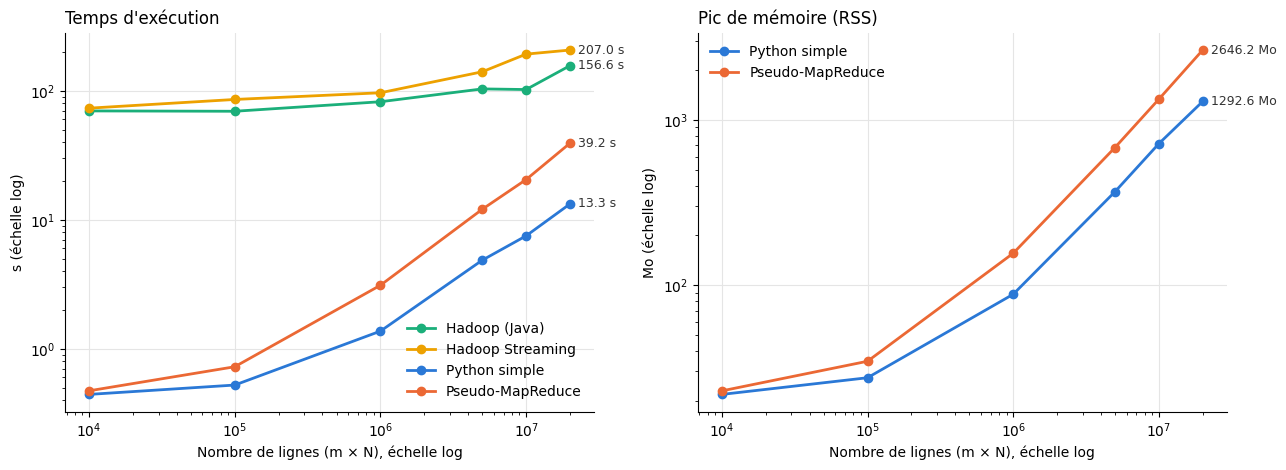

In [15]:
import matplotlib.pyplot as plt

COULEURS = {"python_simple": "#2a78d6", "pseudo_mapreduce": "#eb6834",
            "hadoop_java": "#1baf7a", "hadoop_streaming": "#eda100"}
NOMS = {"python_simple": "Python simple", "pseudo_mapreduce": "Pseudo-MapReduce",
        "hadoop_java": "Hadoop (Java)", "hadoop_streaming": "Hadoop Streaming"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col, titre, unite in [(axes[0], "temps_s", "Temps d'exécution", "s"),
                              (axes[1], "memoire_mo", "Pic de mémoire (RSS)", "Mo")]:
    for methode, g in df.dropna(subset=[col]).groupby("methode", sort=False):
        g = g.sort_values("lignes")
        ax.plot(g["lignes"], g[col], marker="o", markersize=6, linewidth=2,
                color=COULEURS[methode], label=NOMS[methode])
        x, y = g["lignes"].iloc[-1], g[col].iloc[-1]
        ax.annotate(f"{y:.1f} {unite}", (x, y), textcoords="offset points", xytext=(6, 0),
                    va="center", fontsize=9, color="#333333")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Nombre de lignes (m × N), échelle log")
    ax.set_ylabel(unite + " (échelle log)")
    ax.set_title(titre, loc="left", fontsize=12)
    ax.grid(True, which="major", color="#e5e5e5", linewidth=0.8)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/comparaison.png", dpi=130)
plt.show()

### 7.2 Temps de calcul « pur » (sans le démarrage de l'interpréteur)

Les temps ci-dessus incluent le lancement du processus Python (≈ 0,4 s sur ce poste, antivirus compris), qui domine
pour les petits fichiers. On mesure ici le seul calcul, dans le processus courant :

In [16]:
lignes_mesure = []
for m in [1, 10, 100, 500]:
    f = generer_fichier.dupliquer(base, f"data/mots_N{N}_m{m}.txt", m)
    for nom, fn in [("python_simple", wordcount_simple.compter_occurrences),
                    ("pseudo_mapreduce", wordcount_mapreduce.compter_occurrences)]:
        t0 = time.perf_counter(); fn(f); d = time.perf_counter() - t0
        lignes_mesure.append(dict(m=m, lignes=N * m, methode=nom, calcul_s=round(d, 4)))
pur = pd.DataFrame(lignes_mesure).pivot(index=["m", "lignes"], columns="methode", values="calcul_s")
pur["ratio"] = (pur["pseudo_mapreduce"] / pur["python_simple"]).round(2)
pur

,methode,pseudo_mapreduce,python_simple,ratio
m,lignes,,,
1,10000,0.0274,0.0045,6.09
10,100000,0.3298,0.0380,8.68
100,1000000,1.3477,0.4602,2.93
500,5000000,6.8254,2.2995,2.97


### 7.3 Décomposition du temps Hadoop

Temps de copie du fichier dans HDFS (`hdfs dfs -put`, fait une fois par fichier) et coût marginal par million de lignes :

In [17]:
h = df[df["methode"].str.startswith("hadoop")].pivot(index=["m", "lignes", "taille_mo"], columns="methode", values="temps_s")
h["upload_hdfs_s"] = df[df["methode"] == "hadoop_java"].set_index(["m", "lignes", "taille_mo"])["upload_hdfs_s"]
h["streaming / java"] = (h["hadoop_streaming"] / h["hadoop_java"]).round(2)
h

,,methode,hadoop_java,hadoop_streaming,upload_hdfs_s,streaming / java
m,lignes,taille_mo,,,,
1,10000,0.061,69.8456,73.3575,25.829,1.05
10,100000,0.611,69.4127,85.6926,20.558,1.23
100,1000000,6.108,82.2707,96.5480,31.718,1.17
500,5000000,30.541,103.4577,140.4294,59.009,1.36
1000,10000000,61.082,102.2917,192.4923,62.403,1.88
2000,20000000,122.164,156.5946,206.9773,67.582,1.32


In [18]:
# Pente (s par million de lignes) entre le plus petit et le plus gros fichier
for meth in ORDRE:
    g = df[df["methode"] == meth].sort_values("lignes")
    pente = (g["temps_s"].iloc[-1] - g["temps_s"].iloc[0]) / ((g["lignes"].iloc[-1] - g["lignes"].iloc[0]) / 1e6)
    print(f"{NOMS[meth]:<18} temps fixe ≈ {g['temps_s'].iloc[0]:6.1f} s   coût marginal ≈ {pente:5.2f} s / million de lignes")

Python simple      temps fixe ≈    0.4 s   coût marginal ≈  0.64 s / million de lignes
Pseudo-MapReduce   temps fixe ≈    0.5 s   coût marginal ≈  1.94 s / million de lignes
Hadoop (Java)      temps fixe ≈   69.8 s   coût marginal ≈  4.34 s / million de lignes
Hadoop Streaming   temps fixe ≈   73.4 s   coût marginal ≈  6.68 s / million de lignes


### 7.4 Analyse

**Méthode 1 vs méthode 2.** Les deux sont linéaires en la taille du fichier une fois le coût de démarrage de Python amorti,
mais le pseudo-MapReduce est **2,3 à 3 fois plus lent** en temps total dès 1 million de lignes (**≈ 3,1 à 3,5 fois** en temps de calcul pur, § 7.2)
et consomme **environ 2 fois plus de mémoire** : il crée un tuple `(mot, 1)` par mot, puis une liste de `1` par mot distinct,
alors que la méthode 1 incrémente directement un entier. Pour les petits fichiers (m ≤ 10), les deux temps sont quasi identiques
car ils sont dominés par le démarrage de l'interpréteur.

**Limite mémoire des méthodes Python.** Elles chargent toutes les données en RAM sur **une seule machine** : ≈ 0,7 Go pour 10 M de lignes
en méthode 1, ≈ 1,3 Go en méthode 2, ≈ 2,6 Go pour 20 M de lignes. Un fichier de quelques dizaines de Go ne passerait plus.

**Hadoop MapReduce : une grosse latence fixe.** Même pour 10 000 lignes (61 Ko), un job dure **≈ 70 s** dans le benchmark (≈ 50 s lors de la démonstration du § 5.4, selon la charge de la machine),
contre 0,44 s en Python (≈ 100 à 160 fois plus). Le journal du job montre où part ce temps : ≈ 10 s pour démarrer la JVM cliente et soumettre le job,
≈ 30 s pour que YARN lance l'ApplicationMaster, puis ≈ 15 s par phase (lancement d'un conteneur JVM pour le map, puis pour le reduce),
et l'écriture du résultat dans HDFS. Le document de cours mesurait 12 s sur Linux natif ; ici le cluster tourne dans une VM Docker sous Windows
(4 conteneurs + d'autres conteneurs actifs sur la même VM), ce qui multiplie cette latence — mais la conclusion est la même :
**le temps d'un job Hadoop est d'abord un coût fixe**. Entre 10 000 et 1 million de lignes, le temps ne bouge presque pas (70 → 82 s)
alors qu'il est multiplié par 100 en données.

**Le coût marginal ne joue pas en faveur de Hadoop sur une seule machine.** Entre 10 000 et 20 M de lignes, le job Java passe
de 70 à 157 s, soit ≈ 4 s par million de lignes, contre ≈ 0,6 s en Python simple : sur un seul nœud, Hadoop paie en plus la
sérialisation des paires, l'écriture sur disque entre map et reduce et le passage par HDFS. De plus, tous nos fichiers (≤ 122 Mo)
tiennent dans **un seul bloc HDFS de 128 Mo → un seul mapper** : il n'y a **aucun parallélisme**. L'écart relatif se resserre
(×160 pour 61 Ko, ×12 pour 122 Mo) uniquement parce que la latence fixe est amortie, pas parce que Hadoop calcule plus vite.

**Hadoop Streaming vs Java.** Le job Streaming (nos `mapper.py`/`reducer.py`) est 1,05 à 1,9 fois plus lent que le job Java :
les données passent par des pipes vers des processus Python 3.6 externes, et surtout il n'y a **pas de combiner**, donc
chaque `(mot, 1)` est trié et transféré au reducer, alors que le WordCount Java pré-agrège les comptes côté map.

**Upload HDFS.** Copier le fichier dans HDFS coûte de 20 à 68 s (lecture depuis le disque Windows à travers le montage Docker,
écriture dans le DataNode). Dans un vrai déploiement, les données sont produites ou stockées directement dans HDFS ; ce coût
n'existe qu'une fois et pas à chaque job.

**Quand Hadoop devient-il intéressant ?** Quand le volume dépasse la mémoire et le disque d'une machine et que le fichier est découpé
en de nombreux blocs répartis sur **plusieurs nœuds** : avec k nœuds, le temps devient ≈ latence fixe + (volume × coût marginal) / k,
et la tolérance aux pannes, la localité des données et HDFS deviennent indispensables. Pour des fichiers de l'ordre de 100 Mo,
c'est en revanche un outil beaucoup trop lourd.

*Mesures :* méthodes Python = médiane de 3 exécutions, Docker éteint ; Hadoop = 1 exécution par job (≈ 1 à 3 min chacune), donc avec
une incertitude de l'ordre de ± 10 s (par exemple m = 500 et m = 1000 donnent le même temps pour le job Java).

| Méthode | Avantages | Inconvénients | Quand l'utiliser |
|---|---|---|---|
| Python simple | code minimal, la plus rapide sur une machine | tout en RAM, un seul cœur | fichiers qui tiennent en mémoire |
| Pseudo-MapReduce | illustre le modèle map/shuffle/reduce, facile à paralléliser ensuite | ≈ 3× plus lent, 2× plus de mémoire | pédagogie, prototypage d'un job MapReduce |
| Hadoop MapReduce (Java) | passe à l'échelle (To), tolérance aux pannes, données distribuées, combiner | latence de plus d'une minute ici (12 s en natif), installation lourde, écrit sur disque entre les phases | très gros volumes, sur un cluster |
| Hadoop Streaming (Python) | réutilise du code Python dans Hadoop | encore plus lent que Java, pas de combiner par défaut | prototyper un job Hadoop sans écrire de Java |

## 8. Conclusion

- Les trois approches (et les deux variantes Hadoop) donnent **exactement le même résultat**, vérifié par les tests et à chaque taille de fichier du benchmark.
- Sur une seule machine et pour des fichiers de 61 Ko à 122 Mo, **le Python simple est de loin le plus efficace** (0,4 à 13 s) ;
  la version pseudo-MapReduce paie la matérialisation des paires intermédiaires (≈ ×3 en temps de calcul, ×2 en mémoire).
- **Hadoop** met 70 à 160 s (Java) et 73 à 207 s (Streaming) sur ces mêmes fichiers : sa latence fixe (démarrage des JVM, YARN, HDFS)
  domine, et sur un seul nœud avec un seul bloc HDFS il n'y a aucun parallélisme pour la compenser. Il n'est pas fait pour ces volumes,
  mais c'est le seul des trois qui peut traiter des données plus grosses que la mémoire d'une machine, réparties sur un cluster.
- La progression des trois méthodes montre le chemin du concept à la mise en œuvre : le pseudo-MapReduce rend explicite le découpage
  *map → shuffle → reduce* qui permet ensuite à Hadoop de distribuer le calcul. Pour aller plus loin, **Spark** garde ce modèle tout en
  conservant les données en mémoire entre les étapes, ce qui supprime une grande partie de la latence de Hadoop MapReduce.